# Key-Value Retrieval System — Medical QA Seq2Seq with Attention[Database_training]





## Reference
1. BLEU evaluation code adapted from [bangoc123/BLEU](https://github.com/bangoc123/BLEU).
2. Key-Value Retrieval Networks for Task-Oriented Dialogue] (https://arxiv.org/abs/1705.05414).

In [34]:
import torch

print(torch.__version__)
print(torch.version.cuda)


print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_capability(0))

2.12.0.dev20260407+cu128
12.8
NVIDIA GeForce RTX 5090
(12, 0)


In [35]:

import os
import random
import logging
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.multiprocessing as mp
import matplotlib.pyplot as plt
import sacrebleu

from typing import Tuple, List
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer

print("NumPy  version:", np.__version__)
print("Pandas version:", pd.__version__)
print("PyTorch version:", torch.__version__)

NumPy  version: 2.2.6
Pandas version: 2.3.3
PyTorch version: 2.12.0.dev20260407+cu128


In [36]:
import os
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
os.environ["TORCH_USE_CUDA_DSA"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print("Environment set ")

Environment set 


In [37]:

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s — %(levelname)s — %(message)s"
)
logger = logging.getLogger(__name__)

In [38]:

def set_seed(seed: int = 42):
   random.seed(seed)
   np.random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = False

set_seed(42)

In [39]:
class Config:
    def __init__(self):
        # Model
        self.embedding_dim      = 128
        self.hidden_dim         = 256
        self.num_encoder_layers = 2
        self.num_decoder_layers = 2
        self.attention_dim      = 256
        self.dropout            = 0.4

        # Training
        self.batch_size             = 65
        self.num_epochs             = 30
        self.learning_rate          = 3e-4
        self.teacher_forcing_start  = 0.9
        self.teacher_forcing_end  = 0.2
        
        self.grad_clip              = 1.0
        self.valid_ratio            = 0.1
        self.max_seq_len            = 200

        self.grad_accum_steps   = 4
        self.knowledge_dim = 384

        self.model_save_path    = "/home/suman/research/key_value_retrieval/output/seq2seq_best.pth"
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

config = Config()
print(f"Device: {config.device}")

Device: cuda


In [40]:

print(f"CUDA available: {torch.cuda.is_available()}")
!nvidia-smi

CUDA available: True


Mon May 18 16:02:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.58.03              Driver Version: 595.58.03      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:02:00.0 Off |                  N/A |
| 30%   47C    P1            161W /  575W |    8971MiB /  32607MiB |     19%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [41]:
df = pd.read_csv("/home/suman/research/key_value_retrieval/data/medquad.csv")
df

,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea...",NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in ...,NIHSeniorHealth,Glaucoma
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ...",NIHSeniorHealth,Glaucoma
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
...,...,...,...,...
16402,What is (are) Diabetic Neuropathies: The Nerve...,Focal neuropathy appears suddenly and affects ...,NIDDK,Diabetic Neuropathies: The Nerve Damage of Dia...
16403,How to prevent Diabetic Neuropathies: The Nerv...,The best way to prevent neuropathy is to keep ...,NIDDK,Diabetic Neuropathies: The Nerve Damage of Dia...
16404,How to diagnose Diabetic Neuropathies: The Ner...,Doctors diagnose neuropathy on the basis of sy...,NIDDK,Diabetic Neuropathies: The Nerve Damage of Dia...
16405,What are the treatments for Diabetic Neuropath...,The first treatment step is to bring blood glu...,NIDDK,Diabetic Neuropathies: The Nerve Damage of Dia...


Question number 1

**Simple input output dataset**


In [42]:
import pandas as pd
import json

path = '/home/suman/research/key_value_retrieval/sampledata.xlsx' 
newdf = pd.read_excel(path)
newdf

,focus,intent,subject,answer
0,Glaucoma,definition,optic nerve damage,Glaucoma is a group of diseases that can damag...
1,Glaucoma,causes,fluid pressure,It is often caused by a buildup of fluid that ...
2,Glaucoma,symptoms,peripheral vision,"The most common type, open-angle glaucoma, ini..."
3,Glaucoma,treatment,medication/surgery,"While it cannot be cured, it can be controlled..."
4,Glaucoma,risk,demographics,African-Americans over age 40 and everyone ove...
...,...,...,...,...
95,Urinary Tract Infections,risk,menopause,Changes in the vaginal flora and estrogen leve...
96,Urinary Tract Infections,prevention,post-sex hygiene,Urinating shortly after sexual activity can he...
97,Urinary Tract Infections,symptoms,confusion in elderly,"In older adults, a UTI may not cause typical s..."
98,Urinary Tract Infections,diagnosis,urine culture,A urine culture identifies the specific type o...


In [43]:

def generate_json_key(row):
    key_structure = {
        "focus": str(row['focus']).strip(),
        "intent": str(row['intent']).strip(),
        "subject": str(row['subject']).strip()
    }
    return json.dumps(key_structure)

# 3. Apply and Clean
newdf['key_json'] = newdf.apply(generate_json_key, axis=1)

# Keep ONLY the columns you need for the assignment table
# We use 'key_json' as the searchable tag and your answer/explanation as the value
newdf = newdf[['key_json', 'answer']] 

# 4. Save to CSV (This is your final searchable knowledge base)
newdf.to_csv('datasettable.csv', index=False)
newdf

print(df.head())

                                 question  \
0                What is (are) Glaucoma ?   
1                  What causes Glaucoma ?   
2     What are the symptoms of Glaucoma ?   
3  What are the treatments for Glaucoma ?   
4                What is (are) Glaucoma ?   

                                              answer           source  \
0  Glaucoma is a group of diseases that can damag...  NIHSeniorHealth   
1  Nearly 2.7 million people have glaucoma, a lea...  NIHSeniorHealth   
2  Symptoms of Glaucoma  Glaucoma can develop in ...  NIHSeniorHealth   
3  Although open-angle glaucoma cannot be cured, ...  NIHSeniorHealth   
4  Glaucoma is a group of diseases that can damag...  NIHSeniorHealth   

  focus_area  
0   Glaucoma  
1   Glaucoma  
2   Glaucoma  
3   Glaucoma  
4   Glaucoma  


In [44]:
newdf

,key_json,answer
0,"{""focus"": ""Glaucoma"", ""intent"": ""definition"", ...",Glaucoma is a group of diseases that can damag...
1,"{""focus"": ""Glaucoma"", ""intent"": ""causes"", ""sub...",It is often caused by a buildup of fluid that ...
2,"{""focus"": ""Glaucoma"", ""intent"": ""symptoms"", ""s...","The most common type, open-angle glaucoma, ini..."
3,"{""focus"": ""Glaucoma"", ""intent"": ""treatment"", ""...","While it cannot be cured, it can be controlled..."
4,"{""focus"": ""Glaucoma"", ""intent"": ""risk"", ""subje...",African-Americans over age 40 and everyone ove...
...,...,...
95,"{""focus"": ""Urinary Tract Infections"", ""intent""...",Changes in the vaginal flora and estrogen leve...
96,"{""focus"": ""Urinary Tract Infections"", ""intent""...",Urinating shortly after sexual activity can he...
97,"{""focus"": ""Urinary Tract Infections"", ""intent""...","In older adults, a UTI may not cause typical s..."
98,"{""focus"": ""Urinary Tract Infections"", ""intent""...",A urine culture identifies the specific type o...


In [45]:
from sentence_transformers import SentenceTransformer
import pandas as pd
import numpy as np

# model loading
model = SentenceTransformer('all-MiniLM-L6-v2')

# csv file loading
newdf = pd.read_csv('datasettable.csv')

# adding changed json vector 

newdf['vector'] = newdf['key_json'].apply(lambda x: model.encode(x))

print(newdf[['key_json', 'vector']].head(10))

newdf

2026-05-18 16:02:46,860 — INFO — No device provided, using cuda:0
2026-05-18 16:02:47,732 — INFO — Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
/home/suman/research/key_value_retrival/key/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Batches: 100%|██████████| 1/1 [00:00<00:00, 45.40it/s]

                                            key_json  \
0  {"focus": "Glaucoma", "intent": "definition", ...   
1  {"focus": "Glaucoma", "intent": "causes", "sub...   
2  {"focus": "Glaucoma", "intent": "symptoms", "s...   
3  {"focus": "Glaucoma", "intent": "treatment", "...   
4  {"focus": "Glaucoma", "intent": "risk", "subje...   
5  {"focus": "Glaucoma", "intent": "prevention", ...   
6  {"focus": "Glaucoma", "intent": "diagnosis", "...   
7  {"focus": "Glaucoma", "intent": "research", "s...   
8  {"focus": "Glaucoma", "intent": "types", "subj...   
9  {"focus": "Glaucoma", "intent": "anatomy", "su...   

                                              vector  
0  [0.03493085, -0.0063496623, 0.020890193, -0.00...  
1  [0.017602477, 0.011621764, 0.014631918, 0.0050...  
2  [0.056336723, -0.012092457, 0.0023303514, -0.0...  
3  [0.025601665, 0.044346962, -0.008744623, -0.02...  
4  [0.07579215, 0.04008012, -0.02399045, 0.024263...  
5  [0.04250398, 0.042205047, 0.0018697637, -0.016... 

,key_json,answer,vector
0,"{""focus"": ""Glaucoma"", ""intent"": ""definition"", ...",Glaucoma is a group of diseases that can damag...,"[0.03493085, -0.0063496623, 0.020890193, -0.00..."
1,"{""focus"": ""Glaucoma"", ""intent"": ""causes"", ""sub...",It is often caused by a buildup of fluid that ...,"[0.017602477, 0.011621764, 0.014631918, 0.0050..."
2,"{""focus"": ""Glaucoma"", ""intent"": ""symptoms"", ""s...","The most common type, open-angle glaucoma, ini...","[0.056336723, -0.012092457, 0.0023303514, -0.0..."
3,"{""focus"": ""Glaucoma"", ""intent"": ""treatment"", ""...","While it cannot be cured, it can be controlled...","[0.025601665, 0.044346962, -0.008744623, -0.02..."
4,"{""focus"": ""Glaucoma"", ""intent"": ""risk"", ""subje...",African-Americans over age 40 and everyone ove...,"[0.07579215, 0.04008012, -0.02399045, 0.024263..."
...,...,...,...
95,"{""focus"": ""Urinary Tract Infections"", ""intent""...",Changes in the vaginal flora and estrogen leve...,"[0.028194875, 0.04701296, -0.0443639, 0.032388..."
96,"{""focus"": ""Urinary Tract Infections"", ""intent""...",Urinating shortly after sexual activity can he...,"[0.028240543, 0.07100042, -0.03814581, -0.0080..."
97,"{""focus"": ""Urinary Tract Infections"", ""intent""...","In older adults, a UTI may not cause typical s...","[0.05814652, 0.04140106, -0.01939308, 0.008579..."
98,"{""focus"": ""Urinary Tract Infections"", ""intent""...",A urine culture identifies the specific type o...,"[0.040417407, 0.049983863, -0.030514868, -0.04..."


**Above is the answer of question 1c**

In [46]:
from sentence_transformers import SentenceTransformer
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import torch

# Load the same embedder used to create knowledge vectors
embedder = SentenceTransformer('all-MiniLM-L6-v2')

# Knowledge vectors as numpy array (N_knowledge, 384)
knowledge_vectors = np.array(newdf['vector'].tolist())
knowledge_vectors = knowledge_vectors / np.linalg.norm(knowledge_vectors, axis=1, keepdims=True)  # normalize

TOP_K = 10   # number of knowledge entries to retrieve per question

def retrieve_knowledge_for_question(question_text, top_k=TOP_K):
    """Returns a tensor of shape (top_k, 384) with the top‑K knowledge vectors."""
    q_emb = embedder.encode(question_text, normalize_embeddings=True,show_progress_bar=False)  # (384,)
    scores = np.dot(knowledge_vectors, q_emb)   # (N_knowledge,)
    top_indices = np.argsort(scores)[-top_k:][::-1]
    return torch.tensor(knowledge_vectors[top_indices], dtype=torch.float32)

2026-05-18 16:02:54,838 — INFO — No device provided, using cuda:0
2026-05-18 16:02:55,540 — INFO — Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
/home/suman/research/key_value_retrival/key/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [47]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

#  Query
user_query = "What are the common symptoms of diabetes?"


print(f"User Query: {user_query}")
query_vector = model.encode(user_query).reshape(1, -1)


knowledge_vectors = np.array(newdf['vector'].tolist())
scores = cosine_similarity(query_vector, knowledge_vectors).flatten()


newdf['similarity_score'] = scores


top_result = newdf.sort_values(by='similarity_score', ascending=False).iloc[0]

print("\n--- Retrieval Results ---")
print(f"Top Matched JSON Key: {top_result['key_json']}")
print(f"Similarity Score: {top_result['similarity_score']:.004f}")
print(f"Retrieved Answer: {top_result['answer']}")

User Query: What are the common symptoms of diabetes?


Batches: 100%|██████████| 1/1 [00:00<00:00, 53.73it/s]


--- Retrieval Results ---
Top Matched JSON Key: {"focus": "Diabetes", "intent": "symptoms", "subject": "thirst/hunger"}
Similarity Score: 0.4193
Retrieved Answer: Symptoms include extreme thirst, frequent urination, unexplained weight loss, and blurry vision.


In [48]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

#  Query
user_query = "What are the common symptoms of diabetes?"


print(f"User Query: {user_query}")
query_vector = model.encode(user_query).reshape(1, -1)


knowledge_vectors = np.array(newdf['vector'].tolist())
scores = cosine_similarity(query_vector, knowledge_vectors).flatten()


newdf['similarity_score'] = scores


top_result = newdf.sort_values(by='similarity_score', ascending=False).iloc[0]

print("\n--- Retrieval Results ---")
print(f"Top Matched JSON Key: {top_result['key_json']}")
print(f"Similarity Score: {top_result['similarity_score']:.004f}")
print(f"Retrieved Answer: {top_result['answer']}")

User Query: What are the common symptoms of diabetes?


Batches: 100%|██████████| 1/1 [00:00<00:00, 55.69it/s]


--- Retrieval Results ---
Top Matched JSON Key: {"focus": "Diabetes", "intent": "symptoms", "subject": "thirst/hunger"}
Similarity Score: 0.4193
Retrieved Answer: Symptoms include extreme thirst, frequent urination, unexplained weight loss, and blurry vision.


In [49]:
#  non database
import pandas as pd
import json

path = '/home/suman/research/key_value_retrieval/nondatabase.xlsx' 
newdf = pd.read_excel(path)
newdf

,question,answer
0,What is the medical definition of glaucoma?,Glaucoma is a group of diseases that can damag...
1,How does high fluid pressure affect the eye?,"It damages the nerve fibers, leading to vision..."
2,Does open-angle glaucoma hurt?,"No, it initially has no symptoms and causes no..."
3,Can doctors cure glaucoma permanently?,"No, it cannot be cured, but it can be controll..."
4,Is my 65-year-old father at risk for eye issues?,"Yes, people over 60 are at a higher risk for g..."
5,How often should I get a dilated eye exam?,High-risk individuals should go at least every...
6,What happens if I lose my peripheral vision?,It results in tunnel vision and can lead to bl...
7,What are the main types of glaucoma?,The most common are open-angle and angle-closu...
8,How many nerve fibers are in the optic nerve?,There are more than 1 million nerve fibers.
9,Does glaucoma affect both eyes usually?,It can develop in one or both eyes.


In [50]:
#  database
import pandas as pd
import json

path = '/home/suman/research/key_value_retrieval/database.xlsx' 
newdf = pd.read_excel(path)
newdf

,INPUT,OUTPUT
0,What is the definition of glaucoma?,"The definition is: JSON{""focus"": ""Glaucoma"", ""..."
1,What causes eye pressure?,"It is caused by: JSON{""focus"": ""Glaucoma"", ""in..."
2,What are the signs of glaucoma?,"Look for: JSON{""focus"": ""Glaucoma"", ""intent"": ..."
3,How do you treat glaucoma?,"Management includes: JSON{""focus"": ""Glaucoma"",..."
4,Who is at risk for eye damage?,"Risk factors are: JSON{""focus"": ""Glaucoma"", ""i..."
5,How to prevent vision loss?,"Prevention info: JSON{""focus"": ""Glaucoma"", ""in..."
6,How is glaucoma diagnosed?,"The procedure is: JSON{""focus"": ""Glaucoma"", ""i..."
7,Is there research on glaucoma?,"Current studies: JSON{""focus"": ""Glaucoma"", ""in..."
8,What is open-angle glaucoma?,"This type is: JSON{""focus"": ""Glaucoma"", ""inten..."
9,What is the optic nerve?,"Anatomy info: JSON{""focus"": ""Glaucoma"", ""inten..."


In [51]:
print(type(df))

<class 'pandas.core.frame.DataFrame'>


In [52]:
df = df[["question", "answer"]].reset_index(drop=True)
df

,question,answer
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea..."
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in ...
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ..."
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...
...,...,...
16402,What is (are) Diabetic Neuropathies: The Nerve...,Focal neuropathy appears suddenly and affects ...
16403,How to prevent Diabetic Neuropathies: The Nerv...,The best way to prevent neuropathy is to keep ...
16404,How to diagnose Diabetic Neuropathies: The Ner...,Doctors diagnose neuropathy on the basis of sy...
16405,What are the treatments for Diabetic Neuropath...,The first treatment step is to bring blood glu...


In [53]:
class KnowledgeDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=128):
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.PAD_TOKEN_ID = tokenizer.pad_token_id
        self.SOS_TOKEN_ID = tokenizer.sos_token_id
        self.EOS_TOKEN_ID = tokenizer.eos_token_id
        self.df = df   # must contain 'question', 'answer', 'knowledge_vec'

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        question = row['question']
        answer = row['answer']
        knowledge = row['knowledge_vec']   #
        # Encode question – NO special tokens
        enc_ids = self.tokenizer.encode(question, max_length=self.max_len, add_special_tokens=False)
        # Encode answer content – NO special tokens, reserve space for SOS/EOS
        tgt_ids = self.tokenizer.encode(answer, max_length=self.max_len-2, add_special_tokens=False)

        decoder_in = [self.SOS_TOKEN_ID] + tgt_ids
        decoder_out = tgt_ids + [self.EOS_TOKEN_ID]

        # Simple length guards
        if len(decoder_in) == 0:
            decoder_in = [self.SOS_TOKEN_ID]
        if len(decoder_out) == 0:
            decoder_out = [self.EOS_TOKEN_ID]
        if len(decoder_in) > self.max_len:
            decoder_in = decoder_in[:self.max_len-1] + [self.EOS_TOKEN_ID]
            decoder_out = decoder_out[:self.max_len]

        return {
            "encoder_input_ids": torch.tensor(enc_ids, dtype=torch.long),
            "decoder_input_ids": torch.tensor(decoder_in, dtype=torch.long),
            "decoder_output_ids": torch.tensor(decoder_out, dtype=torch.long),
            "knowledge": knowledge,  
        }

In [54]:
def collate_fn_knowledge(batch, pad_token_id: int):
    """
    Pads variable length inputs and outputs and stacks knowledge tensors.
    """
    return {
        "encoder_input_ids": pad_sequence(
            [x["encoder_input_ids"] for x in batch],
            batch_first=True,
            padding_value=pad_token_id
        ),
        "decoder_input_ids": pad_sequence(
            [x["decoder_input_ids"] for x in batch],
            batch_first=True,
            padding_value=pad_token_id
        ),
        "decoder_output_ids": pad_sequence(
            [x["decoder_output_ids"] for x in batch],
            batch_first=True,
            padding_value=-100
        ),
        "knowledge": torch.stack([x["knowledge"] for x in batch]),   
    }

class CollateFnWithKnowledge:
    def __init__(self, pad_token_id: int):
        self.pad_token_id = pad_token_id

    def __call__(self, batch):
        return collate_fn_knowledge(batch, self.pad_token_id)

In [55]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


class BiLSTMEncoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout,
        num_decoder_layers,
        pad_idx=0
    ):
        super().__init__()
        
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.num_decoder_layers = num_decoder_layers
        self.pad_idx = pad_idx

        # Embedding
        self.embedding = nn.Embedding(
            vocab_size, 
            embedding_dim, 
            padding_idx=pad_idx
        )

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.dropout = nn.Dropout(dropout)

        # Project bidirectional states to match decoder hidden size
        self.fc_hidden = nn.Linear(hidden_dim * 2, hidden_dim)
        self.fc_cell = nn.Linear(hidden_dim * 2, hidden_dim)

        self._init_weights()

    def _init_weights(self):
        nn.init.xavier_uniform_(self.embedding.weight)
        
        for name, param in self.lstm.named_parameters():
            if "weight" in name:
                nn.init.xavier_uniform_(param)
            elif "bias" in name:
                nn.init.zeros_(param)
                
        nn.init.xavier_uniform_(self.fc_hidden.weight)
        nn.init.zeros_(self.fc_hidden.bias)
        nn.init.xavier_uniform_(self.fc_cell.weight)
        nn.init.zeros_(self.fc_cell.bias)

    def forward(self, x):
        """
        x: (Batch, Src_Len)
        Returns:
            output:      (B, Src_Len, hidden_dim*2)   ← encoder outputs for attention
            hidden:      (num_decoder_layers, B, hidden_dim)
            cell:        (num_decoder_layers, B, hidden_dim)
            src_mask:    (B, Src_Len)
        """
       
        embedded = self.dropout(self.embedding(x))                    # (B, S, E)

        # ====================== MASK ======================
        src_mask = (x != self.pad_idx).long()                         

        # ====================== PACKED LSTM ======================
        lengths = src_mask.sum(dim=1).cpu()                           # CPU required for pack_padded_sequence
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )

        packed_output, (hidden, cell) = self.lstm(packed)
        output, _ = pad_packed_sequence(
            packed_output, batch_first=True
        )  # (B, S, 2*hidden_dim)

        # ====================== RESHAPE HIDDEN & CELL ======================
        # LSTM output shape for bidirectional: (num_layers * 2, B, hidden_dim)
        hidden = hidden.view(self.num_layers, 2, x.size(0), self.hidden_dim)
        cell = cell.view(self.num_layers, 2, x.size(0), self.hidden_dim)

       
        hidden = torch.cat((hidden[:, 0], hidden[:, 1]), dim=2)   # (num_layers, B, 2*H)
        cell = torch.cat((cell[:, 0], cell[:, 1]), dim=2)         # (num_layers, B, 2*H)

      
        hidden = self.dropout(torch.tanh(self.fc_hidden(hidden)))
        cell = self.dropout(torch.tanh(self.fc_cell(cell)))

       
        if self.num_decoder_layers != self.num_layers:
            hidden = hidden[-1:].repeat(self.num_decoder_layers, 1, 1)
            cell = cell[-1:].repeat(self.num_decoder_layers, 1, 1)

        return output, hidden, cell, src_mask

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ====================== AdditiveAttention (required by decoder) ======================
class AdditiveAttention(nn.Module):
    def __init__(self, enc_hid_dim, dec_hid_dim, attn_dim):
        super().__init__()
        self.encoder_attn = nn.Linear(enc_hid_dim * 2, attn_dim, bias=False)
        self.decoder_attn = nn.Linear(dec_hid_dim, attn_dim, bias=False)
        self.v = nn.Parameter(torch.randn(attn_dim))
        nn.init.uniform_(self.v, -0.1, 0.1)

    def forward(self, encoder_outputs, decoder_hidden, src_mask):
        src_len = encoder_outputs.size(1)
        dec_h = decoder_hidden.unsqueeze(1).repeat(1, src_len, 1)
        energy = torch.tanh(self.encoder_attn(encoder_outputs) + self.decoder_attn(dec_h))
        scores = torch.matmul(energy, self.v)
        scores = scores.masked_fill(src_mask == 0, -1e9)
        weights = F.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs)
        return context.squeeze(1), weights

# ====================== SimpleAttention for knowledge ======================
class SimpleAttention(nn.Module):
    def __init__(self, query_dim, key_dim):
        super().__init__()
        self.scale = key_dim ** -0.5
        self.query_proj = nn.Linear(query_dim, key_dim, bias=False)

    def forward(self, keys, query):
        query = self.query_proj(query).unsqueeze(1)  # (batch, 1, key_dim)
        scores = torch.matmul(query, keys.transpose(1, 2)) * self.scale
        weights = F.softmax(scores, dim=-1)
        context = torch.matmul(weights, keys).squeeze(1)
        return context, weights

class DecoderWithKnowledge(nn.Module):
    def __init__(self, output_dim, embed_dim, encoder_hidden_dim,
                 decoder_hidden_dim, attention_dim, knowledge_dim,
                 num_layers=1, dropout=0.3):
        super().__init__()
        self.output_dim = output_dim
        self.decoder_hidden_dim = decoder_hidden_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(output_dim, embed_dim, padding_idx=0)
        self.attention_enc = AdditiveAttention(encoder_hidden_dim, decoder_hidden_dim, attention_dim)
        self.attention_knw = SimpleAttention(decoder_hidden_dim, knowledge_dim)

        self.rnn = nn.LSTM(
            input_size=embed_dim + (encoder_hidden_dim * 2) + knowledge_dim,
            hidden_size=decoder_hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.fc_out = nn.Linear(decoder_hidden_dim + (encoder_hidden_dim * 2) + knowledge_dim + embed_dim,
                                output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_token, decoder_hidden, decoder_cell, encoder_outputs, src_mask, knowledge_memory):
        embedded = self.dropout(self.embedding(input_token))
        context_enc, _ = self.attention_enc(encoder_outputs, decoder_hidden[-1], src_mask)
        context_enc = context_enc.unsqueeze(1)
        context_knw, _ = self.attention_knw(knowledge_memory, decoder_hidden[-1])
        context_knw = context_knw.unsqueeze(1)

        rnn_input = torch.cat((embedded, context_enc, context_knw), dim=2)
        output, (hidden, cell) = self.rnn(rnn_input, (decoder_hidden, decoder_cell))

        rnn_out = output.squeeze(1)
        emb = embedded.squeeze(1)
        enc_ctx = context_enc.squeeze(1)
        knw_ctx = context_knw.squeeze(1)
        combined = torch.cat((rnn_out, enc_ctx, knw_ctx, emb), dim=1)
        prediction = self.fc_out(combined)
        prediction = prediction.unsqueeze(1)
        return prediction, hidden, cell, None

In [57]:

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, tgt, knowledge_memory, teacher_forcing_ratio=0.5):
        encoder_outputs, hidden, cell, src_mask = self.encoder(src)
        # Ensure mask length matches encoder outputs
        if src_mask.size(1) != encoder_outputs.size(1):
            src_mask = src_mask[:, :encoder_outputs.size(1)]

        batch_size = tgt.size(0)
        trg_len = tgt.size(1)
        output_dim = self.decoder.output_dim
        outputs = torch.zeros(batch_size, trg_len, output_dim).to(src.device)

        input_token = tgt[:, 0:1]   # SOS

        for t in range(1, trg_len):
            output, hidden, cell, _ = self.decoder(
                input_token, hidden, cell, encoder_outputs, src_mask, knowledge_memory
            )
            outputs[:, t:t+1, :] = output

            teacher_force = torch.rand(1).item() < teacher_forcing_ratio
            if teacher_force:
                input_token = tgt[:, t:t+1]
            else:
                input_token = output.argmax(dim=-1)
        return outputs

In [58]:
def generate_causal_mask(size, device):
    """
    Creates a causal mask to prevent attending to future positions.
    
    Args:
        size: sequence length (target length)
        device: cuda/cpu
    
    Returns:
        mask: (size, size) where True means "mask this position" (don't attend)
    """
    # Create upper triangular matrix (excluding diagonal)
    mask = torch.triu(torch.ones(size, size, device=device), diagonal=1).bool()
    return mask  # True = positions to mask out

In [59]:
def evaluate(model, dataloader, criterion, device, pad_token_id, epoch, num_epochs):
    model.eval()
    total_loss = total_correct = total_tokens = 0
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs} [eval] ", leave=True):
            enc_ids = batch["encoder_input_ids"].to(device)
            dec_ids = batch["decoder_input_ids"].to(device)
            tgt_ids = batch["decoder_output_ids"].to(device)

            output  = model(enc_ids, dec_ids, teacher_forcing_ratio=0.0)
            targets = tgt_ids

            min_len = min(output.size(1), targets.size(1))
            output  = output[:, :min_len, :]
            targets = targets[:, :min_len]

            loss = criterion(
                output.contiguous().reshape(-1, output.size(-1)),
                targets.contiguous().reshape(-1)
            )

            mask           = targets != -100          
            total_loss    += loss.item()
            total_correct += (output.argmax(dim=-1) == targets).masked_select(mask).sum().item()
            total_tokens  += mask.sum().item()

    n_tokens = max(total_tokens, 1)                  
    return total_loss / len(dataloader), total_correct / n_tokens

In [60]:
def train_one_epoch(model, dataloader, optimizer, criterion, device,
                    teacher_forcing_ratio, grad_clip, epoch, num_epochs,
                    grad_accum_steps=1):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_tokens = 0
    optimizer.zero_grad()

    progress = tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs} [train]", leave=True)
    for step, batch in enumerate(progress):
        enc_ids = batch["encoder_input_ids"].to(device)
        dec_ids = batch["decoder_input_ids"].to(device)
        tgt_ids = batch["decoder_output_ids"].to(device)
        knowledge = batch["knowledge"].to(device)   # (batch, top_k, 384)

        output = model(enc_ids, dec_ids, knowledge, teacher_forcing_ratio=teacher_forcing_ratio)

        min_len = min(output.size(1), tgt_ids.size(1))
        output = output[:, :min_len, :]
        targets = tgt_ids[:, :min_len]

        loss = criterion(output.reshape(-1, output.size(-1)), targets.reshape(-1))

        scaled_loss = loss / grad_accum_steps
        scaled_loss.backward()

        if (step + 1) % grad_accum_steps == 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)
            optimizer.step()
            optimizer.zero_grad()

        total_loss += loss.item()
        preds = output.argmax(dim=-1)
        mask = (targets != -100)
        total_correct += (preds == targets).masked_select(mask).sum().item()
        total_tokens += mask.sum().item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    if len(dataloader) % grad_accum_steps != 0:
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)
        optimizer.step()
        optimizer.zero_grad()

    avg_loss = total_loss / len(dataloader)
    avg_acc = total_correct / max(total_tokens, 1)
    return avg_loss, avg_acc

In [61]:
@torch.no_grad()
def evaluate(model, dataloader, criterion, device, epoch, num_epochs):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_tokens = 0
    for batch in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs} [eval]", leave=True):
        enc_ids = batch["encoder_input_ids"].to(device)
        dec_ids = batch["decoder_input_ids"].to(device)
        tgt_ids = batch["decoder_output_ids"].to(device)
        knowledge = batch["knowledge"].to(device)   # <-- ADD THIS

        output = model(enc_ids, dec_ids, knowledge, teacher_forcing_ratio=0.0)   # <-- ADD knowledge argument

        min_len = min(output.size(1), tgt_ids.size(1))
        output = output[:, :min_len, :]
        targets = tgt_ids[:, :min_len]

        loss = criterion(output.reshape(-1, output.size(-1)), targets.reshape(-1))
        total_loss += loss.item()
        preds = output.argmax(dim=-1)
        mask = (targets != -100)
        total_correct += (preds == targets).masked_select(mask).sum().item()
        total_tokens += mask.sum().item()

    avg_loss = total_loss / len(dataloader)
    avg_acc = total_correct / max(total_tokens, 1)
    return avg_loss, avg_acc

In [62]:
@torch.no_grad()
def generate_with_knowledge(model, tokenizer, question, device, knowledge_retriever, max_len=120, temperature=0.65):
    model.eval()
    # Retrieve knowledge for this question
    knowledge = knowledge_retriever(question).unsqueeze(0).to(device)   # (1, top_k, 384)

    enc_ids = tokenizer.encode(question, max_length=100, add_special_tokens=False)
    enc_tensor = torch.tensor([enc_ids], device=device)
    encoder_outputs, hidden, cell, src_mask = model.encoder(enc_tensor)

    input_token = torch.tensor([[tokenizer.sos_token_id]], device=device)
    generated = []

    for _ in range(max_len):
        output, hidden, cell, _ = model.decoder(
            input_token, hidden, cell, encoder_outputs, src_mask, knowledge
        )
        logits = output.squeeze(1) / temperature
        probs = torch.softmax(logits, dim=-1)
        top_k = 50
        top_probs, top_indices = torch.topk(probs, top_k, dim=-1)
        top_probs = top_probs / top_probs.sum()
        next_id = top_indices[0, torch.multinomial(top_probs, 1)].item()

        if next_id == tokenizer.eos_token_id:
            break
        generated.append(next_id)
        input_token = torch.tensor([[next_id]], device=device)

    return tokenizer.decode(generated, skip_special_tokens=True)

In [63]:
@torch.no_grad()
def evaluate_bleu(model, dataloader, tokenizer, device, max_batches=50):
    model.eval()
    hypotheses = []
    references = []
    with torch.no_grad():
        for i, batch in enumerate(tqdm(dataloader, desc="Evaluating BLEU")):
            if i >= max_batches:
                break
            enc_ids = batch["encoder_input_ids"].to(device)
            dec_ids = batch["decoder_input_ids"].to(device)
            tgt_ids = batch["decoder_output_ids"]
            knowledge = batch["knowledge"].to(device)   # <-- ADD THIS

            output = model(enc_ids, dec_ids, knowledge, teacher_forcing_ratio=0.0)   # <-- ADD knowledge
            pred_ids = output.argmax(dim=-1).cpu().tolist()
            tgt_list = tgt_ids.tolist()
            for pred, ref in zip(pred_ids, tgt_list):
                skip_tokens = {tokenizer.pad_token_id, tokenizer.eos_token_id}
                pred_clean = [t for t in pred if t not in skip_tokens]
                ref_clean = [t for t in ref if t not in skip_tokens and t != -100]
                hypotheses.append(tokenizer.decode(pred_clean))
                references.append(tokenizer.decode(ref_clean))
    bleu = sacrebleu.corpus_bleu(hypotheses, [references])
    print(f"BLEU-4 Score: {bleu.score:.2f}")
    print(f"BLEU-1: {bleu.precisions[0]:.2f} | BLEU-2: {bleu.precisions[1]:.2f} | BLEU-3: {bleu.precisions[2]:.2f}")
    return bleu.score

In [64]:
import torch
from collections import Counter
import pandas as pd

class SimpleTokenizer:
    def __init__(self, texts, min_freq=2, max_vocab=10000):
        """
        Args:
            texts: list of strings to build vocabulary from
            min_freq: minimum frequency for a token to be included
            max_vocab: maximum vocabulary size (including special tokens)
        """
        self.PAD = "<pad>"
        self.SOS = "<sos>"
        self.EOS = "<eos>"
        self.UNK = "<unk>"

        self.special_tokens = [self.PAD, self.SOS, self.EOS, self.UNK]
        self.word2idx = {}
        self.idx2word = {}

        self.build_vocab(texts, min_freq, max_vocab)

    def tokenize(self, text):
        if not isinstance(text, str):
            text = str(text)
        return text.lower().strip().split()

    def build_vocab(self, texts, min_freq, max_vocab):
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))

        # Special tokens first
        for tok in self.special_tokens:
            self.word2idx[tok] = len(self.word2idx)

        # Determine how many regular tokens we can include
        remaining = max_vocab - len(self.special_tokens)
        # Get most common tokens up to 'remaining'
        most_common = counter.most_common(remaining)
        for word, freq in most_common:
            if freq >= min_freq:
                self.word2idx[word] = len(self.word2idx)

        self.idx2word = {v: k for k, v in self.word2idx.items()}

    def encode(self, text, max_length=None, add_special_tokens=True):
        """
        Encode text to token IDs.
        
        Args:
            text: Input text string
            max_length: Maximum total length (including special tokens if added)
            add_special_tokens: If True, add SOS/EOS tokens
        
        Returns:
            List of token IDs
        """
        if not isinstance(text, str):
            text = str(text)
        
        tokens = self.tokenize(text)
        ids = [self.word2idx.get(t, self.word2idx[self.UNK]) for t in tokens]
        
        # Reserve space for SOS/EOS if they will be added
        if add_special_tokens and max_length is not None:
            content_max_len = max_length - 2
            if len(ids) > content_max_len:
                ids = ids[:content_max_len]
        elif max_length is not None and len(ids) > max_length:
            ids = ids[:max_length]
        
        # Add special tokens if requested
        if add_special_tokens:
            encoded = [self.word2idx[self.SOS]] + ids + [self.word2idx[self.EOS]]
        else:
            encoded = ids
        
        return encoded

    def decode(self, ids, skip_special_tokens=True):
        words = []
        for i in ids:
            # Skip if index doesn't exist
            if i not in self.idx2word:
                continue
            w = self.idx2word[i]
            if skip_special_tokens and w in self.special_tokens:
                continue
            words.append(w)
        return " ".join(words)

    @property
    def vocab_size(self):
        return len(self.word2idx)

    @property
    def pad_token_id(self):
        return self.word2idx[self.PAD]

    @property
    def sos_token_id(self):
        return self.word2idx[self.SOS]

    @property
    def eos_token_id(self):
        return self.word2idx[self.EOS]

In [65]:
def main():
    # ====================== DATA CLEANING ======================
    df_clean = df[["question", "answer"]].copy()
    df_clean = df_clean.dropna().reset_index(drop=True)
    df_clean["question"] = df_clean["question"].astype(str).str.strip()
    df_clean["answer"] = df_clean["answer"].astype(str).str.strip()
    df_clean = df_clean[(df_clean["question"] != "") & (df_clean["answer"] != "")].reset_index(drop=True)
    print(f"Cleaned dataset size: {len(df_clean)} rows")

    # ====================== TOKENIZER ======================
    all_texts = df_clean["question"].tolist() + df_clean["answer"].tolist()
    tokenizer = SimpleTokenizer(texts=all_texts, min_freq=2, max_vocab=10000)
    print(f" Vocabulary size: {tokenizer.vocab_size:,}")
    print(f" PAD: {tokenizer.pad_token_id} | SOS: {tokenizer.sos_token_id} | EOS: {tokenizer.eos_token_id}")

    # ====================== SPLIT DATA ======================
    from sklearn.model_selection import train_test_split
    train_df, valid_df = train_test_split(
        df_clean,
        test_size=config.valid_ratio,
        random_state=42,
        shuffle=True
    )
    train_df = train_df.reset_index(drop=True)
    valid_df = valid_df.reset_index(drop=True)
    print(f"Split completed: {len(train_df)} train / {len(valid_df)} valid")

    # ====================== KNOWLEDGE RETRIEVAL ======================
    print("Retrieving knowledge for training set...")
    train_df['knowledge_vec'] = train_df['question'].apply(lambda q: retrieve_knowledge_for_question(q))
    print("Retrieving knowledge for validation set...")
    valid_df['knowledge_vec'] = valid_df['question'].apply(lambda q: retrieve_knowledge_for_question(q))

    # ====================== DATASETS & DATALOADERS ======================
    train_dataset = KnowledgeDataset(train_df, tokenizer, max_len=config.max_seq_len)
    valid_dataset = KnowledgeDataset(valid_df, tokenizer, max_len=config.max_seq_len)

    train_loader = DataLoader(
        train_dataset, batch_size=config.batch_size, shuffle=True,
        collate_fn=lambda b: collate_fn_knowledge(b, tokenizer.pad_token_id),
        num_workers=0, pin_memory=True
    )
    valid_loader = DataLoader(
        valid_dataset, batch_size=config.batch_size, shuffle=False,
        collate_fn=lambda b: collate_fn_knowledge(b, tokenizer.pad_token_id),
        num_workers=4, pin_memory=True
    )

    # ====================== MODEL ======================
    vocab_size = tokenizer.vocab_size

    encoder = BiLSTMEncoder(
        vocab_size=vocab_size,
        embedding_dim=config.embedding_dim,
        hidden_dim=config.hidden_dim,
        num_layers=config.num_encoder_layers,
        dropout=config.dropout,
        num_decoder_layers=config.num_decoder_layers,
        pad_idx=tokenizer.pad_token_id
    )

    decoder = DecoderWithKnowledge(
        output_dim=vocab_size,
        embed_dim=config.embedding_dim,
        encoder_hidden_dim=config.hidden_dim,
        decoder_hidden_dim=config.hidden_dim,
        attention_dim=config.attention_dim,
        knowledge_dim=384,          # MiniLM embedding dimension
        num_layers=config.num_decoder_layers,
        dropout=config.dropout,
    )

    model = Seq2Seq(encoder, decoder).to(config.device)
    print(f"Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    # ====================== TRAINING SETUP ======================
    criterion = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=0.2)
    optimizer = optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

    train_losses, train_accs = [], []
    val_losses, val_accs = [], []
    best_val_loss = float("inf")
    os.makedirs(os.path.dirname(config.model_save_path), exist_ok=True)

    # ====================== TRAINING LOOP ======================
    for epoch in range(config.num_epochs):
        print(f"\n{'='*60}")
        print(f" Epoch {epoch+1}/{config.num_epochs} | LR: {optimizer.param_groups[0]['lr']:.2e}")
        print(f"{'='*60}")

        denom = max(config.num_epochs - 1, 1)
        tf_ratio = config.teacher_forcing_start - (
            (config.teacher_forcing_start - config.teacher_forcing_end) * (epoch / denom)
        )

        # train_one_epoch and evaluate must be updated to accept knowledge batches
        t_loss, t_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, config.device,
            teacher_forcing_ratio=tf_ratio,
            grad_clip=config.grad_clip,
            epoch=epoch,
            num_epochs=config.num_epochs,
            grad_accum_steps=config.grad_accum_steps,
        )

        v_loss, v_acc = evaluate(
            model, valid_loader, criterion, config.device,
            epoch=epoch, num_epochs=config.num_epochs,
        )

        scheduler.step(v_loss)

        train_losses.append(t_loss)
        train_accs.append(t_acc)
        val_losses.append(v_loss)
        val_accs.append(v_acc)

        print(f" Train → loss: {t_loss:.4f} | acc: {t_acc:.4f}")
        print(f" Valid → loss: {v_loss:.4f} | acc: {v_acc:.4f}")

        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save(model.state_dict(), config.model_save_path)
            print(f" ✓ Best model saved (val_loss={v_loss:.4f})")

    # ====================== FINAL EVALUATION ======================
    print("\n" + "="*70)
    print("FINAL EVALUATION & GENERATION")
    print("="*70)

    model.load_state_dict(torch.load(config.model_save_path))
    # evaluate_bleu must also be updated to handle knowledge (or you can evaluate without knowledge)
    evaluate_bleu(model, valid_loader, tokenizer, config.device)

    # ====================== GENERATION TEST ======================
    print("\n" + "="*70)
    print("SAMPLE GENERATIONS")
    print("="*70)

    test_questions = [
        "What is (are) Glaucoma ?",
        "What causes Glaucoma ?",
        "What are the symptoms of Diabetes ?",
        "How to treat Hypertension ?",
        "What is the treatment for COVID-19 ?"
    ]

    for q in test_questions:
        print(f"\n Question: {q}")
        ans = generate_with_knowledge(
            model, tokenizer, q, config.device,
            knowledge_retriever=retrieve_knowledge_for_question,
            max_len=120, temperature=0.65
        )
        print(f" Answer  : {ans}")
        print("-" * 80)

    # ====================== PLOT TRAINING CURVES ======================
    print("Plotting training curves...")
    epochs = range(1, config.num_epochs + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, train_losses, label="Train Loss", marker="o")
    axes[0].plot(epochs, val_losses,   label="Val Loss",   marker="o")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, train_accs, label="Train Acc", marker="o")
    axes[1].plot(epochs, val_accs,   label="Val Acc",   marker="o")
    axes[1].set_title("Token Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig("/home/suman/research/key_value_retrieval/output/training_curves.png", dpi=150)
    plt.show()

Cleaned dataset size: 16407 rows
 Vocabulary size: 10,000
 PAD: 0 | SOS: 1 | EOS: 2
Split completed: 14766 train / 1641 valid
Retrieving knowledge for training set...
Retrieving knowledge for validation set...
Trainable params: 20,134,416

 Epoch 1/30 | LR: 3.00e-04


Epoch 1/30 [eval]: 100%|██████████| 26/26 [00:25<00:00,  1.01it/s]


 Train → loss: 7.8902 | acc: 0.0435
 Valid → loss: 7.2901 | acc: 0.0521
 ✓ Best model saved (val_loss=7.2901)

 Epoch 2/30 | LR: 3.00e-04


Epoch 2/30 [eval]: 100%|██████████| 26/26 [00:25<00:00,  1.01it/s]


 Train → loss: 7.0435 | acc: 0.0771
 Valid → loss: 7.2831 | acc: 0.0526
 ✓ Best model saved (val_loss=7.2831)

 Epoch 3/30 | LR: 3.00e-04


Epoch 3/30 [eval]: 100%|██████████| 26/26 [00:25<00:00,  1.01it/s]


... (53 outputs left out)

Epoch 30/30 [eval]: 100%|██████████| 26/26 [00:08<00:00,  3.24it/s]


 Train → loss: 6.5629 | acc: 0.1055
 Valid → loss: 6.9054 | acc: 0.0756
 ✓ Best model saved (val_loss=6.9054)

FINAL EVALUATION & GENERATION


Evaluating BLEU: 100%|██████████| 26/26 [00:08<00:00,  3.23it/s]


BLEU-4 Score: 0.61
BLEU-1: 14.83 | BLEU-2: 3.05 | BLEU-3: 0.49

SAMPLE GENERATIONS

 Question: What is (are) Glaucoma ?
 Answer  : is is a is is to the the or of the of of it this this and to brain spinal the the of have the of to and and of or most genetic is and the are the the of the your the people with an with autosomal and in - as is the and eye have are or occurs or of the the the at same cause of the may in the in a of and you have that with syndrome when and be as the and the a
--------------------------------------------------------------------------------

 Question: What causes Glaucoma ?
 Answer  : causes a a caused mutations the when of other as a or on in cause the of most often important the that the genetic the the of in the other the
--------------------------------------------------------------------------------

 Question: What are the symptoms of Diabetes ?
 Answer  : are the in are the of symptoms of symptoms in the not until the a in who that a in of and with and

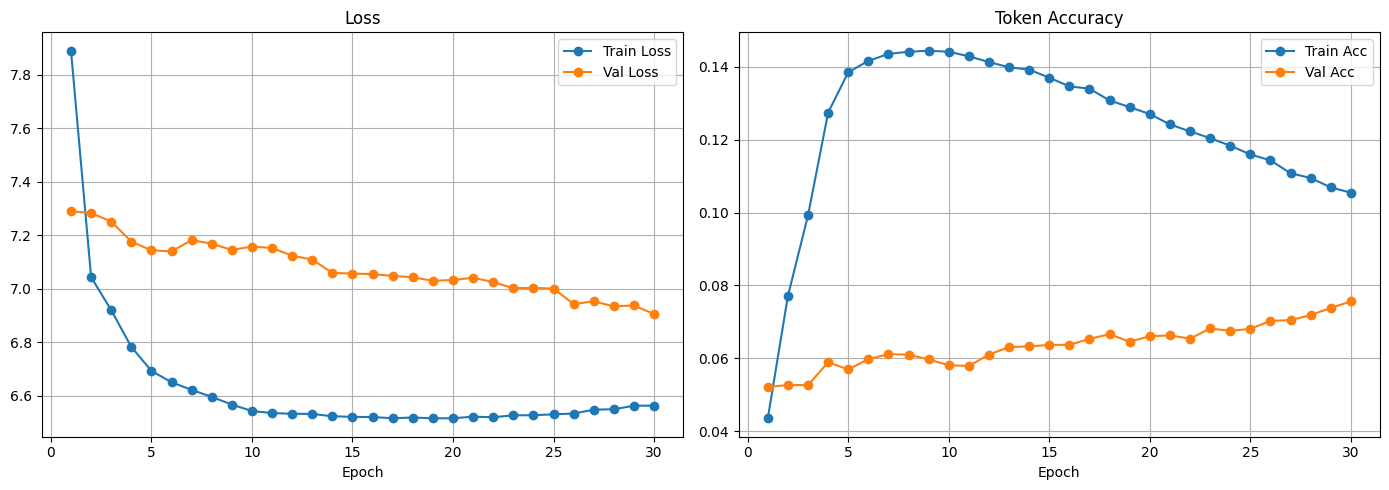

In [66]:


if __name__ == "__main__":
    try:
        mp.set_start_method("spawn", force=False)
    except RuntimeError: 

        
        pass
    main()